# 09c · Programa de inventário cíclico
A acuracidade medida é **96%** por endereço contado (Fase 4), abaixo da meta usual de CD (≥ 98–99%).
Perguntas:
1. Onde estão os erros (tipo de endereço, classe ABC, motivo)?
2. A contagem atual cobre o que importa?
3. Qual programa de contagem dá cobertura por risco, e quanto custa?

*EN summary: cycle-count diagnosis (accuracy by location type, ABC class and error reason; coverage)
and a risk-based ABC counting program with frequency, daily workload and cost.*

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dcanalysis import q, save, savefig, log, params, register_saving, ROOT, OUT

NB = "09c"
PH9 = ROOT / "reports" / "phase9"
P = params(); C = P["costs"]
K = P["simulation"]["scale_factor"]
FATOR_PAGO = 1 / (P["labor"]["utilization_target"] * (1 - P["labor"]["absenteeism"]))
c_op = P["labor_cost"]["picker_brl_h"] * FATOR_PAGO
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)

abc = pd.read_csv(OUT / "sku_abc_xyz.csv", sep=";", decimal=",")[["sku_id", "abc"]]
cc = q("""SELECT c.*, l.location_type, l.zone FROM fact_cycle_count c JOIN dim_location l ON l.location_id = c.location_id""")
cc["sku_ref"] = cc.system_sku_id.fillna(cc.counted_sku_id)
cc = cc.merge(abc, left_on="sku_ref", right_on="sku_id", how="left")
cc["ok"] = cc.reason_code == "OK"
# Natureza do erro: QUANTIDADE (contagem/separação/recebimento) × ENDEREÇO (putaway / remanejamento)
cc["natureza"] = cc.reason_code.map({"OK": "ok", "COUNT_ERROR": "quantidade",
                                     "FOUND_UNEXPECTED": "endereço", "MISPLACED": "endereço", "NOT_FOUND": "endereço"})

## 1. Diagnóstico da acuracidade

In [2]:
por = lambda col: cc.groupby(col).agg(contagens=("ok", "size"), acuracidade_pct=("ok", lambda s: 100 * s.mean())).round(1)
display(por("abc"), por("location_type"), por("zone"))
nat = cc[~cc.ok].natureza.value_counts().to_frame("erros")
nat["pct_dos_erros"] = (100 * nat.erros / nat.erros.sum()).round(1)
nat

,contagens,acuracidade_pct
abc,,
A,1480,95.1
B,1104,96.2
C,1847,96.5


,contagens,acuracidade_pct
location_type,,
overflow,57,100.0
pick,947,97.0
reserve,3427,95.6


,contagens,acuracidade_pct
zone,,
chilled,553,96.6
dry,3360,96.0
frozen,518,95.2


,erros,pct_dos_erros
natureza,,
quantidade,114,63.7
endereço,65,36.3


**Leitura:**
- Erros de **quantidade** (~2/3) e de **endereço** (~1/3) têm causas diferentes. Quantidade vem de
  conferência no recebimento e de separação (pegar a mais/a menos). Endereço vem do putaway errado
  (Fase 4: turno 2 e operador 3).
- O **pulmão** erra mais que a face de picking: lá estão os paletes guardados no putaway e mexidos pela retrátil.
- A acuracidade dos itens **A** não é melhor que a dos C. Hoje a contagem **não prioriza risco**.

## 2. Cobertura da contagem atual

In [3]:
dias = q("SELECT COUNT(DISTINCT date_key) AS d FROM fact_inventory_daily").d[0]
pal_classe = q("""SELECT i.sku_id, SUM(i.n_pallets) * 1.0 / :d AS paletes_medios FROM fact_inventory_daily i
                  GROUP BY i.sku_id""", d=int(dias)).merge(abc, on="sku_id")   # int(): o sqlite não aceita int do numpy
loc_classe = pal_classe.groupby("abc").paletes_medios.sum() * K                     # ~1 endereço por palete
cont_ano = cc.groupby("abc").size() / 2 * K
cobertura = pd.DataFrame({"enderecos_ocupados": loc_classe.round(0), "contagens_ano_atual": cont_ano.round(0)})
cobertura["vezes_por_ano_atual"] = (cobertura.contagens_ano_atual / cobertura.enderecos_ocupados).round(2)
print(f"Contagens por dia hoje (escala cheia): {len(cc) / 2 * K / 300:.0f} (só no turno 1)")
cobertura

Contagens por dia hoje (escala cheia): 74 (só no turno 1)


,enderecos_ocupados,contagens_ano_atual,vezes_por_ano_atual
abc,,,
A,5613.0,7400.0,1.32
B,3527.0,5520.0,1.57
C,4849.0,9235.0,1.90


## 3. Programa proposto: frequência por classe ABC + contagens por gatilho
| Classe | Frequência | Por quê |
|---|---|---|
| A | mensal (12×/ano) | 80% da receita; erro vira ruptura cara |
| B | trimestral (4×/ano) | risco médio |
| C | semestral (2×/ano) | pouca receita |

Mais **contagens por gatilho**, quase gratuitas porque o operador já está no endereço:
- **contagem no zero:** quando o WMS diz que o endereço esvaziou, o separador confirma;
- **contagem na divergência:** separador não achou o item, contagem imediata;
- **pós-putaway por amostragem** no turno 2 até a taxa de erro cair (Fase 4).

In [4]:
freq = {"A": 12, "B": 4, "C": 2}
prog = cobertura.copy()
prog["frequencia_ano"] = prog.index.map(freq)
prog["contagens_ano_proposto"] = prog.enderecos_ocupados * prog.frequencia_ano
dias_uteis = 300
min_cont = C["count_min_per_location"]
tot_atual, tot_prop = prog.contagens_ano_atual.sum(), prog.contagens_ano_proposto.sum()
resumo = pd.DataFrame({
    "contagens_ano": [tot_atual, tot_prop],
    "contagens_dia": [tot_atual / dias_uteis, tot_prop / dias_uteis],
    "horas_ano": [tot_atual * min_cont / 60, tot_prop * min_cont / 60],
    "pessoas_dedicadas": [tot_atual * min_cont / 60 / (dias_uteis * P["labor"]["shift_hours"] * P["labor"]["utilization_target"]),
                          tot_prop * min_cont / 60 / (dias_uteis * P["labor"]["shift_hours"] * P["labor"]["utilization_target"])],
}, index=["atual", "proposto"])
resumo["custo_ano_R$"] = resumo.horas_ano * c_op
save(prog.reset_index().round(1), "09c_programa_contagem", out=PH9)
save(resumo.reset_index(names="programa").round(1), "09c_programa_resumo", out=PH9)
display(prog.round(0), resumo.round(1))

,enderecos_ocupados,contagens_ano_atual,vezes_por_ano_atual,frequencia_ano,contagens_ano_proposto
abc,,,,,
A,5613.0,7400.0,1.0,12,67356.0
B,3527.0,5520.0,2.0,4,14108.0
C,4849.0,9235.0,2.0,2,9698.0


,contagens_ano,contagens_dia,horas_ano,pessoas_dedicadas,custo_ano_R$
atual,22155.0,73.8,1107.8,0.5,38411.1
proposto,91162.0,303.9,4558.1,2.2,158051.8


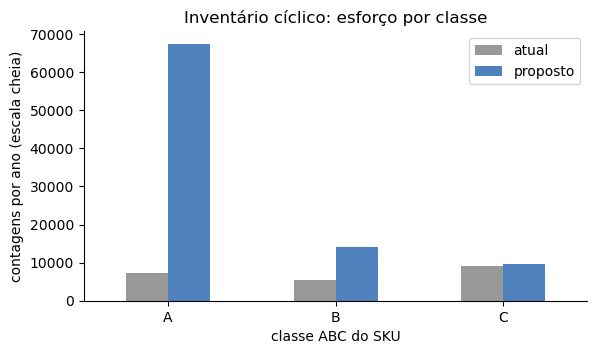

In [5]:
# Barras agrupadas: contagens/ano atuais × propostas por classe (mostra a realocação do esforço).
fig, ax = plt.subplots(figsize=(6.5, 3.5))
prog[["contagens_ano_atual", "contagens_ano_proposto"]].plot.bar(ax=ax, rot=0, color=["#999999", "#4F81BD"])
ax.set_ylabel("contagens por ano (escala cheia)"); ax.set_xlabel("classe ABC do SKU")
ax.legend(["atual", "proposto"]); ax.set_title("Inventário cíclico: esforço por classe")
savefig(fig, "09c_programa_contagem", out=PH9)

**Leitura:**
- Hoje o esforço é **invertido**: os itens C são contados com mais frequência (1,9×/ano) que os A
  (1,3×/ano). O programa proposto leva os A a 12×/ano e mantém os C em 2×/ano.
- Custo: de ~74 para ~300 contagens por dia, ≈ 2 pessoas dedicadas, ≈ R$ 120 mil/ano a mais. É pequeno
  perto do custo de uma ruptura de item A ou de um palete "perdido" no frio.
- Meta: **acuracidade ≥ 98,5%** por endereço em 6 meses. Os indicadores de acompanhamento são a
  acuracidade por classe, a natureza do erro (quantidade × endereço) e o turno de origem.
- A contagem sozinha só **detecta**. A **prevenção** está nos POPs: leitura obrigatória do endereço no
  putaway (POP-02) e conferência por leitura de código na separação (POP-03).

In [6]:
register_saving(9, "Programa de inventário cíclico por ABC (custo adicional)", "horas de contagem/ano",
                round(resumo.loc["atual", "horas_ano"]), round(resumo.loc["proposto", "horas_ano"]),
                "acuracidade 96% -> meta 98,5%", "custo de hora paga; escala cheia",
                -(resumo.loc["proposto", "custo_ano_R$"] - resumo.loc["atual", "custo_ano_R$"]), 0)
log(NB, "acuracidade por classe/tipo/zona/natureza; cobertura = contagens/ano ÷ endereços ocupados (~1 por palete); "
        "programa ABC 12/4/2 por ano + gatilhos")